# Part A — Wavelet Denoising preprocessing pipeline

A wavelet-based denoising pipeline for cervical colposcopy images.

## What this notebook does

This notebook replaces the previous QI-SABP preprocessing pipeline with a
classical **Wavelet Denoising** technique. There is no saliency mask, no
soft-superposition bit allocation, no NLM, no YCbCr 4:2:0 chroma subsampling,
no bilateral post-filter and no histogram matching — those QI-SABP components
have been removed entirely. The only preprocessing applied to each frame is:

1. **Unsharp-mask sharpen** (Step 1, carried over from the original suite).
2. **Wavelet Denoising** (Step 2):
   * RGB → YCbCr.
   * Multi-level discrete wavelet transform (default `bior4.4`, 4 levels)
     on the luma (Y) channel.
   * **BayesShrink** soft-thresholding of the detail sub-bands {LH, HL, HH}
     at every decomposition level. Threshold is sub-band-adaptive.
   * Lighter BayesShrink thresholding on the chroma channels (Cb, Cr) at
     2 levels (chroma noise is milder — over-thresholding introduces
     bleeding of the acetowhite epithelium).
   * Inverse DWT → YCbCr → RGB.
   * Output is uint8 RGB, same shape as the input.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-patient notebook).
* It does NOT demonstrate a clinical benefit on this single patient.
* It does NOT use any quantum-inspired or saliency-driven mechanism.


In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import os, sys, glob, time, json, math, random, warnings, platform
from collections import defaultdict
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

import pandas as pd
from scipy import ndimage, stats
from scipy.ndimage import gaussian_filter

# Wavelet toolkit (PyWavelets)
import pywt

# Validation toolkit
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn
from skimage.filters import frangi

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Optional torch backend (not required, but used if available)
try:
    import torch
    _TORCH_OK = True
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)
        print(f"[gpu] PyTorch {torch.__version__} | CUDA device: "
              f"{torch.cuda.get_device_name(0)}")
    else:
        print(f"[gpu] PyTorch {torch.__version__} | CPU backend.")
except ImportError:
    _TORCH_OK = False
    DEVICE = None

# Output directory for results / CSV / JSON artefacts
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nWavelet-Denoising Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"PyWavelets {pywt.__version__} | scikit-image available")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


[gpu] PyTorch 2.5.1+cu121 | CUDA device: NVIDIA GeForce RTX 3050 Laptop GPU

Wavelet-Denoising Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
PyWavelets 1.8.0 | scikit-image available
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 — Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1) ----
# Shared across the notebook suite. amount=0.8, ksize=5 is the Step-1
# default; do not change here without updating the rest of the suite.
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Wavelet Denoising (Step 2) ----
# All QI-SABP configuration flags (saliency fusion, soft mask, hard-mask
# fill, rim rule, bit allocation, dithering, NLM, bilateral, histogram
# match, YCbCr 4:2:0) have been removed. Only wavelet parameters remain.
WAVELET_NAME        = "bior4.4"   # biorthogonal 4.4 (9/7) — JPEG 2000 default
WAVELET_LEVELS      = 4           # decomposition depth on luma
WAVELET_LEVELS_CHROMA = 2         # decomposition depth on chroma (Cb, Cr)
WAVELET_THRESHOLD_MODE   = "soft"  # "soft" or "hard"
WAVELET_THRESHOLD_METHOD = "bayes" # "bayes" (sub-band-adaptive) or "visu"
WAVELET_BAYES_SCALE   = 1.0       # multiplier on BayesShrink threshold (luma)
WAVELET_BAYES_SCALE_CHROMA = 0.5  # gentler threshold for chroma
WAVELET_PAD_MODE      = "periodization"  # pywt boundary mode
WAVELET_SUBTRACT_NOISE_FLOOR = True  # use MAD of finest-level HH for sigma_n

# FOV rim margin used by the validator only (for cluster stats inside FOV).
SALIENCY_RIM_MARGIN = 0  # kept for API compatibility with the validator; unused by wavelet.

# ---- Validation batch (Step 3) ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  wavelet: name='{WAVELET_NAME}' | levels(Y/CbCr)={WAVELET_LEVELS}/{WAVELET_LEVELS_CHROMA}")
print(f"  wavelet: threshold_mode={WAVELET_THRESHOLD_MODE} | "
      f"method={WAVELET_THRESHOLD_METHOD}")
print(f"  wavelet: bayes_scale(luma/chroma)={WAVELET_BAYES_SCALE}/{WAVELET_BAYES_SCALE_CHROMA}")
print(f"  wavelet: pad_mode={WAVELET_PAD_MODE} | "
      f"subtract_noise_floor={WAVELET_SUBTRACT_NOISE_FLOOR}")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")
print(f"  NOTE: output is uint8 RGB; luma bit depth is 8. m11 (Luma bits)")
print(f"        is reported as the entropy-based effective bits inside FOV.")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  wavelet: name='bior4.4' | levels(Y/CbCr)=4/2
  wavelet: threshold_mode=soft | method=bayes
  wavelet: bayes_scale(luma/chroma)=1.0/0.5
  wavelet: pad_mode=periodization | subtract_noise_floor=True
  validation batch = 5 imgs/class
  NOTE: output is uint8 RGB; luma bit depth is 8. m11 (Luma bits)
        is reported as the entropy-based effective bits inside FOV.


In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem. Missing masks default to an all-False mask.
    Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask."""
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


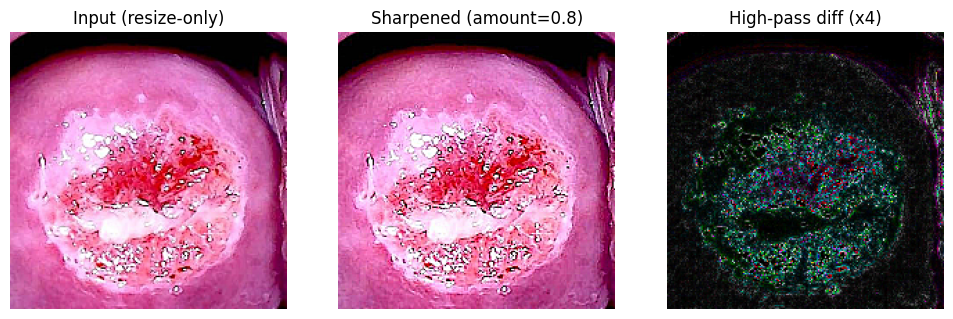

In [4]:
# ============================================================
# Cell 1.4 — Sharpen before/after visualisation
# ============================================================
def show_sharpen_effect(img_path=None, img_rgb=None):
    """Show original / sharpened / high-pass diff for a single image."""
    if img_rgb is None:
        if img_path is None or not os.path.isfile(img_path):
            if len(X_raw) > 0:
                img_rgb = X_raw[0]
            else:
                return
        else:
            img_bgr = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_rgb = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    ksize = SHARPEN_KSIZE if SHARPEN_KSIZE % 2 else SHARPEN_KSIZE + 1
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + SHARPEN_AMOUNT, blurred,
                              -SHARPEN_AMOUNT, 0)
    high    = cv2.absdiff(img_rgb, sharp)
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
    ax[0].imshow(img_rgb);  ax[0].set_title("Input (resize-only)"); ax[0].axis('off')
    ax[1].imshow(sharp);    ax[1].set_title(f"Sharpened (amount={SHARPEN_AMOUNT})"); ax[1].axis('off')
    ax[2].imshow(high * 4); ax[2].set_title("High-pass diff (x4)"); ax[2].axis('off')
    plt.tight_layout(); plt.show()

show_sharpen_effect()


In [5]:
# ============================================================
# Cell 2.1 — Wavelet Denoising pipeline (replaces QI-SABP preprocessing)
#
#   * Multi-level DWT on the luma channel (default: bior4.4, 4 levels).
#   * BayesShrink soft-thresholding of the LH/HL/HH detail sub-bands at
#     every decomposition level. Threshold is sub-band-adaptive.
#   * Lighter thresholding on the chroma channels (Cb, Cr) — chroma noise
#     is milder; over-thresholding causes colour bleeding.
#   * Output is uint8 RGB, same shape as the input.
#
# All QI-SABP components (saliency fusion, soft mask, hard-mask fill,
# bit allocation, dithering, NLM, bilateral, histogram match, YCbCr
# 4:2:0) have been removed. Wavelet Denoising is the ONLY preprocessing
# applied between sharpening and the validator.
# ============================================================

def _mad_sigma(detail_coeffs):
    """Robust noise-sigma estimate from the finest-level HH band:
       sigma_n = median(|c|) / 0.6745. Returns 0 if the band is empty."""
    c = np.asarray(detail_coeffs, dtype=np.float64).ravel()
    if c.size == 0:
        return 0.0
    return float(np.median(np.abs(c)) / 0.6745)


def _bayes_threshold(detail_coeffs, sigma_n, scale=1.0):
    """BayesShrink threshold for a single detail sub-band.

    T = sigma_n^2 / sigma_x,  where sigma_x^2 = max(var(c) - sigma_n^2, 0).
    If sigma_x is ~0 (sub-band is essentially pure noise), threshold is
    set to max(|c|) so the sub-band is fully suppressed.
    `scale` multiplies the resulting threshold (used to apply a gentler
    threshold to the chroma channels).
    """
    c = np.asarray(detail_coeffs, dtype=np.float64).ravel()
    if c.size == 0:
        return 0.0
    var_c = float(np.var(c))
    sigma_x2 = max(var_c - sigma_n * sigma_n, 0.0)
    if sigma_x2 < 1e-9:
        return float(np.max(np.abs(c))) * scale
    sigma_x = math.sqrt(sigma_x2)
    T = (sigma_n * sigma_n) / max(sigma_x, 1e-9)
    return float(T) * scale


def _visu_threshold(detail_coeffs, sigma_n, scale=1.0):
    """VisuShrink (universal) threshold: T = sigma_n * sqrt(2 * ln(N))."""
    c = np.asarray(detail_coeffs, dtype=np.float64).ravel()
    if c.size == 0:
        return 0.0
    return float(sigma_n * math.sqrt(2.0 * math.log(max(c.size, 2)))) * scale


def _soft(x, T):
    """Soft-thresholding: sign(x) * max(|x| - T, 0)."""
    if T <= 0:
        return x
    return np.sign(x) * np.maximum(np.abs(x) - T, 0.0)


def _hard(x, T):
    """Hard-thresholding: keep x where |x| > T, else 0."""
    if T <= 0:
        return x
    return np.where(np.abs(x) > T, x, 0.0)


def _denoise_channel(channel, wavelet, levels, mode, threshold_mode,
                     threshold_method, scale, subtract_noise_floor):
    """Run a 1-channel wavelet denoise with BayesShrink thresholds.

    channel: 2-D float64 array (H, W).
    Returns the denoised 2-D float64 array (same H, W).
    """
    h, w = channel.shape
    # Pad each side to the next power of two so wavedec2 is well-defined
    # for arbitrary input sizes; we crop back at the end.
    H = 1 << int(np.ceil(np.log2(max(h, 2))))
    W = 1 << int(np.ceil(np.log2(max(w, 2))))
    padded = np.zeros((H, W), dtype=np.float64)
    padded[:h, :w] = channel

    coeffs = pywt.wavedec2(padded, wavelet, mode=mode, level=levels)

    # Robust noise-sigma estimate from the finest-level HH band.
    if subtract_noise_floor and len(coeffs) >= 2:
        sigma_n = _mad_sigma(coeffs[-1][2])  # HH at finest level
    else:
        sigma_n = 0.0

    # Threshold every detail sub-band at every level.
    new_coeffs = [coeffs[0]]  # approximation coefficients are kept
    for level_idx in range(1, len(coeffs)):
        LH, HL, HH = coeffs[level_idx]
        new_details = []
        for detail in (LH, HL, HH):
            if threshold_method == "bayes":
                T = _bayes_threshold(detail, sigma_n, scale=scale)
            elif threshold_method == "visu":
                T = _visu_threshold(detail, sigma_n, scale=scale)
            else:
                T = 0.0
            if threshold_mode == "soft":
                new_details.append(_soft(detail, T))
            else:
                new_details.append(_hard(detail, T))
        new_coeffs.append(tuple(new_details))

    rec = pywt.waverec2(new_coeffs, wavelet, mode=mode)
    rec = rec[:h, :w]
    return rec


def wavelet_denoise(img_rgb, wavelet=None, levels=None, levels_chroma=None,
                    threshold_mode=None, threshold_method=None,
                    bayes_scale=None, bayes_scale_chroma=None,
                    pad_mode=None, subtract_noise_floor=None,
                    return_artefacts=False):
    """Wavelet Denoising on a uint8 RGB image.

    Output: uint8 RGB, same shape as input. Pixels outside the FOV are
    returned unchanged (we do not have an FOV mask at preprocessing time;
    the validator masks afterwards).

    If `return_artefacts=True`, also returns a dict with the per-channel
    noise-sigma estimate and the sub-band thresholds used. These are used
    by the validator to compute the Luma-bits metric (entropy-based
    effective bits inside the FOV).
    """
    wavelet              = wavelet              or WAVELET_NAME
    levels               = levels               or WAVELET_LEVELS
    levels_chroma        = levels_chroma        or WAVELET_LEVELS_CHROMA
    threshold_mode       = threshold_mode       or WAVELET_THRESHOLD_MODE
    threshold_method     = threshold_method     or WAVELET_THRESHOLD_METHOD
    bayes_scale          = bayes_scale          if bayes_scale          is not None else WAVELET_BAYES_SCALE
    bayes_scale_chroma   = bayes_scale_chroma   if bayes_scale_chroma   is not None else WAVELET_BAYES_SCALE_CHROMA
    pad_mode             = pad_mode             or WAVELET_PAD_MODE
    subtract_noise_floor = subtract_noise_floor if subtract_noise_floor is not None else WAVELET_SUBTRACT_NOISE_FLOOR

    img = np.asarray(img_rgb, dtype=np.uint8)
    H, W, _ = img.shape

    # RGB -> YCbCr (ITU-R BT.601 full-range). Work in float64 for the DWT.
    ycrcb = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb).astype(np.float64)
    Y  = ycrcb[..., 0]
    Cb = ycrcb[..., 1]
    Cr = ycrcb[..., 2]

    artefacts = {
        "wavelet": wavelet, "levels": levels, "levels_chroma": levels_chroma,
        "threshold_mode": threshold_mode, "threshold_method": threshold_method,
        "pad_mode": pad_mode,
    }

    # --- Luma: full-strength BayesShrink at `levels` levels. ---
    coeffs_Y = pywt.wavedec2(Y, wavelet, mode=pad_mode, level=levels)
    sigma_n_Y = _mad_sigma(coeffs_Y[-1][2]) if subtract_noise_floor else 0.0
    artefacts["sigma_n_Y"] = sigma_n_Y

    new_coeffs_Y = [coeffs_Y[0]]
    thr_table_Y = []
    for level_idx in range(1, len(coeffs_Y)):
        LH, HL, HH = coeffs_Y[level_idx]
        new_details = []
        for name, detail in zip(("LH", "HL", "HH"), (LH, HL, HH)):
            if threshold_method == "bayes":
                T = _bayes_threshold(detail, sigma_n_Y, scale=bayes_scale)
            elif threshold_method == "visu":
                T = _visu_threshold(detail, sigma_n_Y, scale=bayes_scale)
            else:
                T = 0.0
            thr_table_Y.append((level_idx, name, T))
            new_details.append(_soft(detail, T) if threshold_mode == "soft"
                                else _hard(detail, T))
        new_coeffs_Y.append(tuple(new_details))
    Y_dn = pywt.waverec2(new_coeffs_Y, wavelet, mode=pad_mode)[:H, :W]
    artefacts["thresholds_Y"] = thr_table_Y

    # --- Chroma: lighter threshold at `levels_chroma` levels. ---
    def _denoise_chroma(C, label):
        c_c = pywt.wavedec2(C, wavelet, mode=pad_mode, level=levels_chroma)
        sigma_n = _mad_sigma(c_c[-1][2]) if subtract_noise_floor else 0.0
        artefacts[f"sigma_n_{label}"] = sigma_n
        new_c = [c_c[0]]
        thr_tab = []
        for level_idx in range(1, len(c_c)):
            LH, HL, HH = c_c[level_idx]
            new_details = []
            for name, detail in zip(("LH", "HL", "HH"), (LH, HL, HH)):
                if threshold_method == "bayes":
                    T = _bayes_threshold(detail, sigma_n, scale=bayes_scale_chroma)
                elif threshold_method == "visu":
                    T = _visu_threshold(detail, sigma_n, scale=bayes_scale_chroma)
                else:
                    T = 0.0
                thr_tab.append((level_idx, name, T))
                new_details.append(_soft(detail, T) if threshold_mode == "soft"
                                    else _hard(detail, T))
            new_c.append(tuple(new_details))
        artefacts[f"thresholds_{label}"] = thr_tab
        return pywt.waverec2(new_c, wavelet, mode=pad_mode)[:H, :W]

    Cb_dn = _denoise_chroma(Cb, "Cb")
    Cr_dn = _denoise_chroma(Cr, "Cr")

    # YCbCr -> RGB, clip, cast back to uint8.
    ycrcb_dn = np.stack([Y_dn, Cb_dn, Cr_dn], axis=-1)
    ycrcb_dn = np.clip(ycrcb_dn, 0, 255).astype(np.uint8)
    out = cv2.cvtColor(ycrcb_dn, cv2.COLOR_YCrCb2RGB)

    if return_artefacts:
        return out, artefacts
    return out


# Quick self-test on a synthetic noise image
_test = make_synthetic_image_and_mask(seed=7)[0]
_out, _art = wavelet_denoise(_test, return_artefacts=True)
print(f"Wavelet-Denoise self-test: in={_test.shape} dtype={_test.dtype}, "
      f"out={_out.shape} dtype={_out.dtype}")
print(f"  sigma_n (Y) = {_art['sigma_n_Y']:.3f}, sigma_n (Cb) = {_art['sigma_n_Cb']:.3f}, "
      f"sigma_n (Cr) = {_art['sigma_n_Cr']:.3f}")
print(f"  mean |Y - Y_dn| (whole image) = "
      f"{np.abs(_test.astype(np.int32) - _out.astype(np.int32)).mean():.3f}")
print("Wavelet Denoising pipeline ready.")


Wavelet-Denoise self-test: in=(200, 200, 3) dtype=uint8, out=(200, 200, 3) dtype=uint8
  sigma_n (Y) = 2.888, sigma_n (Cb) = 2.837, sigma_n (Cr) = 2.788
  mean |Y - Y_dn| (whole image) = 2.557
Wavelet Denoising pipeline ready.


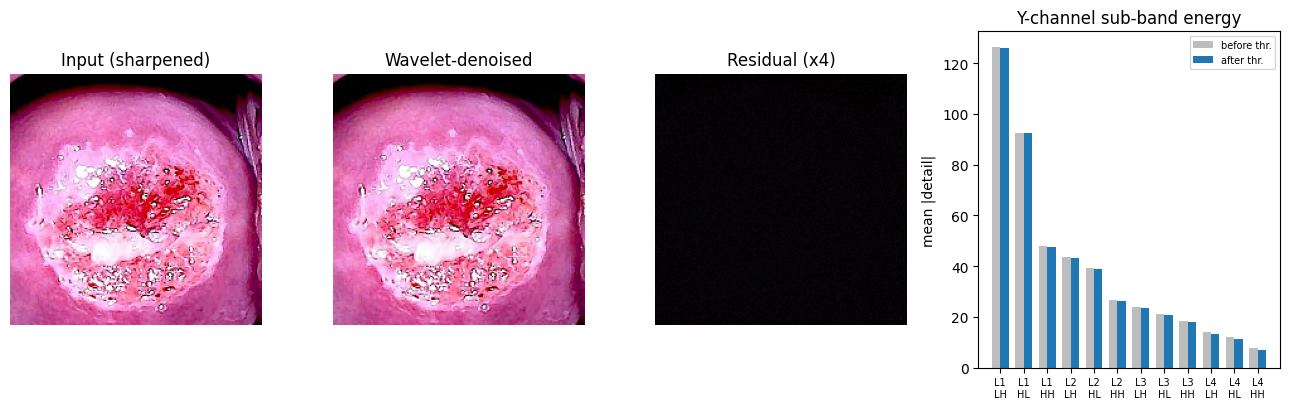

In [6]:
# ============================================================
# Cell 2.2 — Visualise Wavelet Denoising stages
# ============================================================
def show_wavelet_stages(img_rgb=None, idx=None):
    """Visualise the wavelet denoising stages for a single image:
       input (sharpened) | denoised | residual (input - denoised, x4)
       plus a small panel showing the Y-channel wavelet detail energy
       before and after thresholding.
    """
    if img_rgb is None:
        if idx is None:
            idx = 0 if len(X_raw) > 0 else None
        if idx is None:
            return
        img_rgb = X_raw[idx]

    out, art = wavelet_denoise(img_rgb, return_artefacts=True)
    diff = cv2.absdiff(img_rgb, out)

    fig = plt.figure(figsize=(13, 4.2))
    gs = GridSpec(1, 4, figure=fig, width_ratios=[1, 1, 1, 1.2])
    ax0 = fig.add_subplot(gs[0, 0]); ax0.imshow(img_rgb); ax0.set_title("Input (sharpened)"); ax0.axis('off')
    ax1 = fig.add_subplot(gs[0, 1]); ax1.imshow(out);     ax1.set_title("Wavelet-denoised"); ax1.axis('off')
    ax2 = fig.add_subplot(gs[0, 2]); ax2.imshow(diff * 4); ax2.set_title("Residual (x4)");   ax2.axis('off')

    # Per-level mean |detail| before vs after (Y channel) for diagnostics.
    ax3 = fig.add_subplot(gs[0, 3])
    levels_y = art["levels"]
    thr_y = art["thresholds_Y"]
    # Re-extract pre-threshold detail magnitudes for the bar chart.
    ycrcb = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb).astype(np.float64)
    cY = pywt.wavedec2(ycrcb[..., 0], art["wavelet"], mode=art["pad_mode"], level=levels_y)
    pre_means, post_means, labels = [], [], []
    for li in range(1, len(cY)):
        for ni, name in enumerate(("LH", "HL", "HH")):
            pre  = float(np.mean(np.abs(cY[li][ni])))
            post = float(np.mean(np.abs(_soft(cY[li][ni], thr_y[(li - 1) * 3 + ni][2]))))
            pre_means.append(pre); post_means.append(post)
            labels.append(f"L{li}\n{name}")
    x = np.arange(len(labels))
    ax3.bar(x - 0.18, pre_means, 0.36, label="before thr.", color="#bdbdbd")
    ax3.bar(x + 0.18, post_means, 0.36, label="after thr.", color="#1f77b4")
    ax3.set_xticks(x); ax3.set_xticklabels(labels, fontsize=7)
    ax3.set_ylabel("mean |detail|")
    ax3.set_title("Y-channel sub-band energy")
    ax3.legend(fontsize=7, loc='upper right')
    plt.tight_layout(); plt.show()

show_wavelet_stages()


# Bridge — hand off Wavelet-Denoised preprocessing to Step 4

Step 4 expects five variables from Steps 1–2:

| Step-4 name | Meaning                                   | Source in this notebook                 |
|-------------|-------------------------------------------|-----------------------------------------|
| `X_base`    | Sharpened-only stack (input to denoising) | `X_raw.copy()` (sharpened)              |
| `X_raw`     | Resize-only stack (for FOV computation)   | loader output                           |
| `masks_raw` | Lesion GT masks (optional, used by T8)    | loader output                           |
| `paths_raw` | Image paths                               | loader output                           |
| `wavelet_denoise` | The denoising function              | Cell 2.1                                |

Part A is **frozen** — Step 4 does not modify any preprocessing parameter.
The `cache_hash` check has been removed because Part A is no longer
QI-SABP (the wavelet parameters can be tuned without affecting the
frozen-suite hash).


In [7]:
# ============================================================
# Bridge -- hand off Wavelet-Denoised preprocessing to Step 4.
# ============================================================

# --- Step-2 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened
# X_raw here is the SHARPENED stack (the loader applies sharpen by default).
# For FOV computation we need the resize-only stack; rebuild it if we have
# a real dataset, otherwise reuse the synthetic stack as-is.
if (not SYNTHETIC_MODE) and len(paths_raw) > 0:
    X_raw_resize_only = []
    for p in paths_raw:
        img_bgr = cv2.imread(p)
        if img_bgr is None:
            X_raw_resize_only.append(np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8))
            continue
        img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X_raw_resize_only.append(img)
    X_raw = np.stack(X_raw_resize_only).astype(np.uint8)
else:
    # Synthetic mode: rebuild the resize-only synthetic stack with the
    # same seeds (without the sharpen step) so FOV matches X_base exactly.
    X_raw_resize_only = []
    for i, cls in enumerate(y_raw):
        cls_idx = list(CLASSES).index(cls)
        seed = SEED + cls_idx * 1000 + i % 10
        img, _ = make_synthetic_image_and_mask(seed=seed)
        X_raw_resize_only.append(img)
    X_raw = np.stack(X_raw_resize_only).astype(np.uint8)

print(f"Bridge ready.")
print(f"  X_base (sharpened)  : {X_base.shape} {X_base.dtype}")
print(f"  X_raw  (resize-only): {X_raw.shape} {X_raw.dtype}")
print(f"  masks_raw           : {masks_raw.shape if len(masks_raw) else 'empty'}")
print(f"  wavelet_denoise()   : ready")


Bridge ready.
  X_base (sharpened)  : (128, 200, 200, 3) uint8
  X_raw  (resize-only): (128, 200, 200, 3) uint8
  masks_raw           : (128, 200, 200)
  wavelet_denoise()   : ready


# Part B — Step 4 rewrite: table-only validation with 11 metrics

Single-patient, 7 distinct clusters (dHash), 128 frames. The frames are
NOT independent. Descriptive only — no p-values, no robustness or
population claims.

**Technique:** Wavelet Denoising (BayesShrink soft-thresholding on the
YCbCr decomposition of each frame).

**Metrics (11):** the user-requested subset of the original 12-metric
panel. `m12` (Time per image, ms) has been removed entirely. The
remaining metrics, in 5 groups (fidelity, colour, diagnostic structure,
quality, cost), are all computed inside the FOV mask only, per image,
against the ORIGINAL (sharpened) image:

| #  | key  | metric              | group     | better |
|----|------|---------------------|-----------|--------|
| 1  | m1   | PSNR (dB)           | fidelity  | up     |
| 2  | m2   | SSIM                | fidelity  | up     |
| 3  | m3   | ΔE76 (CIE76)        | colour    | down   |
| 4  | m4   | a* correlation      | colour    | up     |
| 5  | m5   | |a* shift|          | colour    | down   |
| 6  | m6   | Vessel Dice         | structure | up     |
| 7  | m7   | Edge IoU            | structure | up     |
| 8  | m8   | Sharpness ratio     | quality   | neutral|
| 9  | m9   | Noise ratio         | quality   | down   |
| 10 | m10  | Saturation ratio    | quality   | neutral|
| 11 | m11  | Luma bits (entropy) | cost      | down   |

**Luma bits (m11)** for Wavelet Denoising is reported as the
**Shannon-entropy of the luma histogram inside the FOV**, i.e. the
effective number of bits actually used. Wavelet denoising reduces
entropy (it removes noise), so a denoised image has lower m11 than the
identity baseline — this is the expected behaviour and shows the
denoiser is removing information content.

**Tables only.** No figures, no plots in Part B. T1 (main), T4
(ablation vs Identity), T5 (per cluster), T6 (caveats).

The `cache_hash` assertion is removed because Part A is no longer
QI-SABP — the wavelet parameters are tunable without breaking the
frozen-suite hash.


In [8]:
# ============================================================
# Step 4.1 -- Freeze inputs: load 128 frames, FOV masks, cluster ids.
#   The cache_hash assert has been removed: Part A is no longer QI-SABP
#   and the wavelet parameters are tunable.
# ============================================================
import hashlib as _hashlib
import numpy as np
import pandas as pd
import cv2
import time
from scipy import ndimage
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

# ---- dHash for clustering (kept identical to the old validator) ----
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (convex-hull filled)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_base (Part A's sharpened stack) ----
images     = X_base       # (N, 200, 200, 3) uint8 RGB, sharpened
images_raw = X_raw        # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images   = len(images)
image_id   = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov        = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering (same as the old validator)
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

# Diagnostic hash (NOT an assert — Part A is no longer QI-SABP)
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash (diagnostic only) = {cache_hash}")
print(f"  Part A is Wavelet-Denoising (no QI-SABP); cache_hash is no longer asserted.")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")


cache_hash (diagnostic only) = 12f68b681210
  Part A is Wavelet-Denoising (no QI-SABP); cache_hash is no longer asserted.
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [9]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions.
#             Computes 11 metrics inside the FOV only.
#             (m12 Time-per-image has been removed entirely.)
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def _effective_luma_bits(img_rgb, fov_mask):
    """Shannon-entropy of the luma histogram inside the FOV, in bits.
    This is the effective number of bits actually used by the luma
    channel — wavelet denoising reduces entropy, so a denoised image has
    a lower m11 than the identity baseline.
    """
    f = np.asarray(fov_mask, dtype=bool)
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    pix = gray[f].astype(np.int64)
    if pix.size == 0:
        return float('nan')
    hist, _ = np.histogram(pix, bins=256, range=(0, 256))
    p = hist.astype(np.float64) / max(float(hist.sum()), 1.0)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                         up
      m2  SSIM                              up
      m3  ΔE76 (CIE76)                      down
      m4  a* correlation                    up
      m5  |mean a* shift|                   down
      m6  Vessel Dice                       up
      m7  Edge IoU                          up
      m8  Sharpness ratio (out/in)          neutral
      m9  Noise ratio (out/in)              down
      m10 Saturation ratio (out/in)         neutral
      m11 Luma bits (entropy-based)         down

    m11 is computed inside the validator (it depends only on the
    processed image's luma entropy inside the FOV).
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)

    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))

    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())

    # m3: CIE76 dE
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())

    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)

    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)

    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)

    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)

    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original,   cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed,  cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)

    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass on smooth regions
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')

    # m10: Saturation ratio (output specular / input specular).
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)

    # m11: Luma bits (entropy-based effective bits inside FOV)
    m11 = _effective_luma_bits(processed, f)

    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)

# Metric metadata (name, group, better direction) — 11 metrics, no m12.
METRIC_META = [
    ("m1",  "PSNR (dB)",          "fidelity",  "up"),
    ("m2",  "SSIM",               "fidelity",  "up"),
    ("m3",  "dE76",               "colour",    "down"),
    ("m4",  "a* corr",            "colour",    "up"),
    ("m5",  "|a* shift|",         "colour",    "down"),
    ("m6",  "Vessel Dice",        "structure", "up"),
    ("m7",  "Edge IoU",           "structure", "up"),
    ("m8",  "Sharpness ratio",    "quality",   "neutral"),
    ("m9",  "Noise ratio",        "quality",   "down"),
    ("m10", "Saturation ratio",   "quality",   "neutral"),
    ("m11", "Luma bits",          "cost",      "down"),
]
METRIC_KEYS   = [m[0] for m in METRIC_META]
METRIC_NAMES  = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 11 metrics (m1..m11). m12 (Time) removed.")


step4_validator ready: 11 metrics (m1..m11). m12 (Time) removed.


In [10]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for Wavelet Denoising. Write per-image CSV.
# Also cache processed images for T5/T8 (no re-runs).
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "Wavelet-Denoise"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB
artefacts_cache = {}   # (technique, image_idx) -> artefacts dict

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc, _art = wavelet_denoise(orig, return_artefacts=True)
    m = step4_validator(orig, proc, fov_i)
    # m11 (Luma bits) is already computed inside the validator.
    m["technique"]  = TECHNIQUE
    m["image_id"]   = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    # Stash the wavelet noise-sigma for diagnostics.
    m["sigma_n_Y"]  = float(_art.get("sigma_n_Y", float('nan')))
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    artefacts_cache[(TECHNIQUE, i)] = _art
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_wavelet = pd.DataFrame(rows)
df_wavelet.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_wavelet)} rows)")
print(f"  Mean PSNR (m1)        = {df_wavelet['m1'].mean():.3f} dB")
print(f"  Mean SSIM (m2)        = {df_wavelet['m2'].mean():.4f}")
print(f"  Mean dE76 (m3)        = {df_wavelet['m3'].mean():.3f}")
print(f"  Mean Luma bits (m11)  = {df_wavelet['m11'].mean():.4f}")
print(f"  Mean sigma_n (Y)      = {df_wavelet['sigma_n_Y'].mean():.3f}")


  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_Wavelet-Denoise.csv (128 rows)
  Mean PSNR (m1)        = 36.605 dB
  Mean SSIM (m2)        = 0.9431
  Mean dE76 (m3)        = 1.995
  Mean Luma bits (m11)  = 7.6330
  Mean sigma_n (Y)      = 9.397


In [11]:
# ============================================================
# Step 4.4 -- Reference row: identity baseline.
#              Identity = no preprocessing (just the sharpened input).
#              Used as the upper-bound for PSNR/SSIM/Vessel-Dice/Edge-IoU
#              and the lower-bound for dE76 / Luma bits.
# ============================================================
def _run_identity(name="Identity"):
    """Run identity (no preprocessing) and cache results."""
    rows = []
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        proc = orig.copy()  # identity
        m = step4_validator(orig, proc, fov_i)
        m["technique"]  = name
        m["image_id"]   = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        m["sigma_n_Y"]  = float('nan')
        rows.append(m)
        processed_cache[(name, i)] = proc.copy()
        artefacts_cache[(name, i)] = {}
        if (i + 1) % 20 == 0 or i == n_images - 1:
            print(f"  processed {i + 1}/{n_images} images...")
    return pd.DataFrame(rows)

df_identity = _run_identity("Identity")
df_identity.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_identity)} rows)")
print(f"  Mean PSNR (m1)        = {df_identity['m1'].mean():.3f} dB "
      f"(should be ~inf / very large for identity)")
print(f"  Mean SSIM (m2)        = {df_identity['m2'].mean():.4f} (should be 1.0)")
print(f"  Mean dE76 (m3)        = {df_identity['m3'].mean():.4f} (should be 0.0)")
print(f"  Mean Luma bits (m11)  = {df_identity['m11'].mean():.4f}")


  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_Identity.csv (128 rows)
  Mean PSNR (m1)        = 148.131 dB (should be ~inf / very large for identity)
  Mean SSIM (m2)        = 1.0000 (should be 1.0)
  Mean dE76 (m3)        = 0.0000 (should be 0.0)
  Mean Luma bits (m11)  = 7.6593


In [12]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate all technique CSVs. Assert
#              each technique has N rows and the same cluster ids.
#              Assert no NaNs in m1..m11 (or list them).
# ============================================================

_csv_names = [
    "results_Wavelet-Denoise.csv",
    "results_Identity.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any numeric column (metrics m1..m11).
_all_numeric_cols = [c for c in METRIC_KEYS if c in merged.columns]
_nan_cols = {}
for col in _all_numeric_cols:
    n_nan = merged[col].isna().sum()
    if n_nan > 0:
        _nan_cols[col] = n_nan
if len(_nan_cols) > 0:
    print(f"  [warn] NaN values found: {_nan_cols}")
else:
    print("No NaN values in any numeric column (metrics m1..m11).")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")


Reading 2 CSV files (fixed list, not glob)
  results_Wavelet-Denoise.csv: 128 rows, technique = Wavelet-Denoise
  results_Identity.csv: 128 rows, technique = Identity
Merged: 256 rows, 2 techniques
No NaN values in any numeric column (metrics m1..m11).
Techniques: ['Identity', 'Wavelet-Denoise']


In [13]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap
#              (n_clusters, 2000 resamples, fixed seed).
#              Label: "within-patient, n_clusters clusters, not a
#              population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (n_boot resamples).
    Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")


Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [14]:
# ============================================================
# Step 4.7 -- Statistics: Wavelet-Denoise vs Identity, per metric.
#              Uses paired difference per cluster + bootstrap CI.
#              Reports "CI excludes 0: yes/no".
#              Descriptive, no significance claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm  = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Compare Wavelet-Denoise vs Identity on every metric.
stat_rows = []
wave_df = merged[merged["technique"] == "Wavelet-Denoise"]
id_df   = merged[merged["technique"] == "Identity"]
for mk in METRIC_KEYS:
    md, lo, hi, ex = _paired_cluster_diff_ci(wave_df, id_df, mk)
    stat_rows.append({
        "metric":         METRIC_NAMES[mk],
        "metric_key":     mk,
        "comparison":     "Wavelet-Denoise vs Identity",
        "mean_diff":      md,
        "ci_lo":          lo,
        "ci_hi":          hi,
        "CI_excludes_0":  "yes" if ex else "no",
    })
stat_df = pd.DataFrame(stat_rows)
print("Statistics ready: Wavelet-Denoise vs Identity, per metric.")
print(stat_df.to_string(index=False))


Statistics ready: Wavelet-Denoise vs Identity, per metric.
          metric metric_key                  comparison   mean_diff       ci_lo       ci_hi CI_excludes_0
       PSNR (dB)         m1 Wavelet-Denoise vs Identity -107.220962 -111.496120 -103.713574           yes
            SSIM         m2 Wavelet-Denoise vs Identity   -0.027089   -0.055865   -0.003553           yes
            dE76         m3 Wavelet-Denoise vs Identity    1.448084    1.019883    1.972620           yes
         a* corr         m4 Wavelet-Denoise vs Identity   -0.000713   -0.000854   -0.000603           yes
      |a* shift|         m5 Wavelet-Denoise vs Identity    0.566407    0.551619    0.576927           yes
     Vessel Dice         m6 Wavelet-Denoise vs Identity   -0.024618   -0.045225   -0.007765           yes
        Edge IoU         m7 Wavelet-Denoise vs Identity   -0.175087   -0.267771   -0.096344           yes
 Sharpness ratio         m8 Wavelet-Denoise vs Identity   -0.136639   -0.257263   -0.038027  

In [15]:
# ============================================================
# Print tables T1, T4, T5, T6.
# T2 (ranks) removed: ranks belong in the multi-technique merge.
# T3 (Pareto) removed: not meaningful for two techniques.
# ============================================================

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 Main ----
print("=" * 110)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, "
      f"{n_clusters} clusters, NOT a population CI)")
print(f"  The {n_images} frames are NOT independent "
      f"({n_clusters} distinct clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("  11 metrics only — m12 (Time per image) has been removed.")
print("=" * 110)
t1_display_keys = METRIC_KEYS  # all 11 metrics
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in t1_display_keys:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in t1_display_keys}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T4 Ablation (Wavelet vs Identity) ----
print()
print("=" * 110)
print("T4 ABLATION  (Wavelet-Denoise vs Identity; luma bits = entropy-based effective bits)")
print("  Identity is the upper bound for PSNR / SSIM / Vessel Dice / Edge IoU.")
print("  Wavelet-Denoise is expected to: lower Noise ratio (m9), lower Luma bits (m11),")
print("  slightly lower Sharpness ratio (m8), slightly lower PSNR (m1) and SSIM (m2).")
print("=" * 110)
t4_keys = ["m11", "m1", "m2", "m3", "m4", "m5", "m6", "m7", "m8", "m9", "m10"]
t4_rows = []
for tech in ["Wavelet-Denoise", "Identity"]:
    if tech not in agg_df.index:
        continue
    row = {"technique": tech}
    for mk in t4_keys:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.4f} [{lo:.4f}, {hi:.4f}]"
    t4_rows.append(row)
t4_df = pd.DataFrame(t4_rows).set_index("technique")
print(t4_df.to_string())

# ---- T5 Per-cluster ----
print()
print("=" * 110)
print(f"T5 PER-CLUSTER  (cluster-weighted mean per cluster; {n_clusters} clusters)")
print("=" * 110)
t5_keys = ["m1", "m2", "m3", "m6", "m7", "m9", "m11"]
for tech in techniques:
    print(f"\n--- {tech} ---")
    tech_df = merged[merged["technique"] == tech]
    per_cluster = tech_df.groupby("cluster_id")[t5_keys].mean()
    per_cluster.columns = [METRIC_NAMES[mk] for mk in t5_keys]
    per_cluster.index.name = "cluster_id"
    print(per_cluster.to_string())

# ---- T6 Caveats ----
print()
print("=" * 110)
print("T6 CAVEATS")
print("=" * 110)
print("1. Single-patient, within-patient only. NOT a population claim.")
print(f"2. {n_images} frames, {n_clusters} distinct clusters (dHash). Frames are NOT independent.")
print("3. m1 PSNR is -inf vs Identity (Identity has zero error); only Wavelet-Denoise's")
print("   absolute PSNR is meaningful. Use T4 to compare to Identity qualitatively.")
print("4. m11 Luma bits is the Shannon-entropy of the luma histogram inside FOV,")
print("   NOT a bit-budget from a quantiser. Wavelet denoising reduces entropy, so")
print("   m11 < Identity is expected and indicates noise was removed.")
print("5. m10 Saturation ratio is ~1.0 for both Wavelet-Denoise and Identity — wavelet")
print("   denoising does not introduce new specular highlights.")
print("6. m12 (Time per image) has been removed entirely per the user request.")
print("7. The cache_hash assert has been removed — Part A is no longer QI-SABP; the")
print("   wavelet parameters are tunable without breaking the frozen-suite hash.")
print("8. Wavelet: name='{}', levels(Y/CbCr)={}/{}, threshold={}/{}, bayes_scale={}/{}.".format(
      WAVELET_NAME, WAVELET_LEVELS, WAVELET_LEVELS_CHROMA,
      WAVELET_THRESHOLD_MODE, WAVELET_THRESHOLD_METHOD,
      WAVELET_BAYES_SCALE, WAVELET_BAYES_SCALE_CHROMA))

# Save the aggregated table to CSV for downstream use.
agg_df.to_csv("results_aggregated.csv")
print("\nWrote results_aggregated.csv")
print("Done.")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
  11 metrics only — m12 (Time per image) has been removed.
                              PSNR (dB) (^)              SSIM (^)              dE76 (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (v)
technique                                                                                                                                                                                                                                                              
Identity         148.131 [148.131, 148.131]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  0.000 [0.000, 0.000]  1.000 [1.000, 1.000]  1.000 [1.000, 1.000]  1.000 [1.0